In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

file_path = Path("../data/raw/naca2412_re200000.txt")

with open(file_path, "r") as f:
    lines = f.readlines()

header_index = None

for i, line in enumerate(lines):
    if "alpha" in line and "CL" in line and "CD" in line:
        header_index = i
        break

print("Header found at line:", header_index)

Header found at line: 10


In [2]:
data = pd.read_csv(
    file_path,
    sep=r"\s+",
    skiprows=header_index + 2,
    names=[
        "alpha",
        "CL",
        "CD",
        "CDp",
        "CM",
        "Top_Xtr",
        "Bot_Xtr"
    ]
)

data.head()

,alpha,CL,CD,CDp,CM,Top_Xtr,Bot_Xtr
0,-6.0,-0.5764,0.01932,0.01146,-0.0269,1.0000,0.0732
1,-5.0,-0.4440,0.01696,0.00910,-0.0326,0.9892,0.1012
2,-4.0,-0.2831,0.01488,0.00731,-0.0437,0.9703,0.1744
3,-3.0,-0.1341,0.01311,0.00623,-0.0520,0.9456,0.3341
4,-2.0,0.0018,0.01113,0.00549,-0.0563,0.9178,0.6297


In [3]:
print(data)

print("\nNumber of aerodynamic operating points:", len(data))

print("\nMissing values:")
print(data.isna().sum())

    alpha      CL       CD      CDp      CM  Top_Xtr  Bot_Xtr
0    -6.0 -0.5764  0.01932  0.01146 -0.0269   1.0000   0.0732
1    -5.0 -0.4440  0.01696  0.00910 -0.0326   0.9892   0.1012
2    -4.0 -0.2831  0.01488  0.00731 -0.0437   0.9703   0.1744
3    -3.0 -0.1341  0.01311  0.00623 -0.0520   0.9456   0.3341
4    -2.0  0.0018  0.01113  0.00549 -0.0563   0.9178   0.6297
5    -1.0  0.1160  0.01010  0.00515 -0.0527   0.8804   0.8777
6    -0.0  0.2825  0.00998  0.00478 -0.0608   0.8320   0.9790
7     1.0  0.4222  0.00981  0.00418 -0.0663   0.7641   1.0000
8     2.0  0.5162  0.01010  0.00407 -0.0625   0.6925   1.0000
9     3.0  0.6110  0.01068  0.00433 -0.0587   0.6256   1.0000
10    4.0  0.7057  0.01144  0.00483 -0.0549   0.5612   1.0000
11    5.0  0.7997  0.01228  0.00552 -0.0511   0.4918   1.0000
12    6.0  0.8917  0.01328  0.00638 -0.0471   0.4122   1.0000
13    7.0  0.9769  0.01477  0.00760 -0.0424   0.3033   1.0000
14    8.0  1.0467  0.01776  0.00993 -0.0362   0.1646   1.0000
15    9.

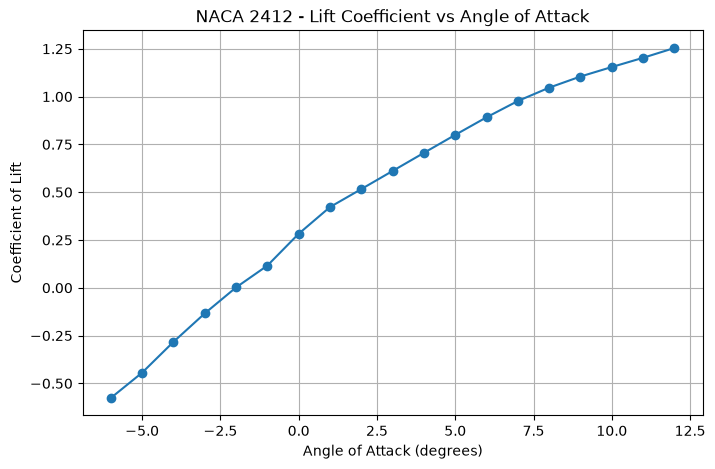

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(
    data["alpha"],
    data["CL"],
    marker="o"
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Coefficient of Lift")
plt.title("NACA 2412 - Lift Coefficient vs Angle of Attack")
plt.grid()

plt.show()

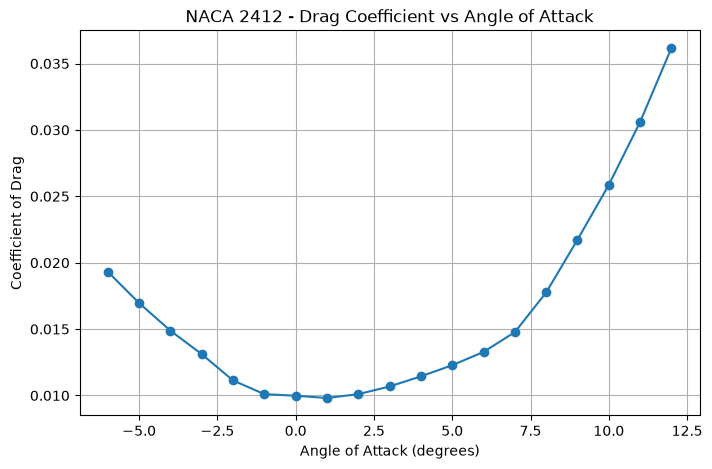

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    data["alpha"],
    data["CD"],
    marker="o"
)

plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Coefficient of Drag")
plt.title("NACA 2412 - Drag Coefficient vs Angle of Attack")
plt.grid()

plt.show()

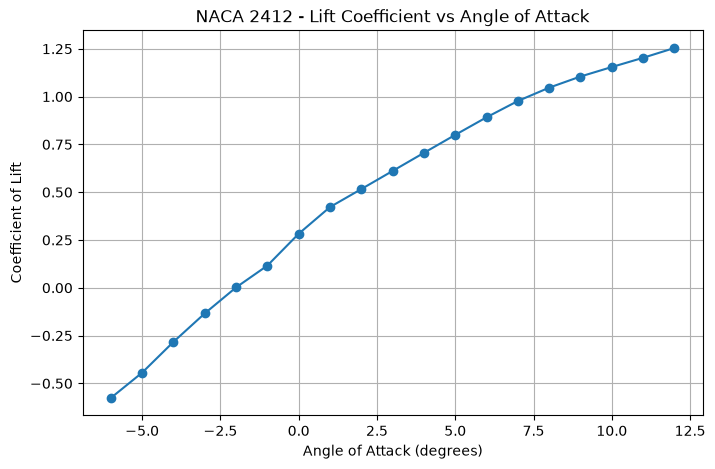

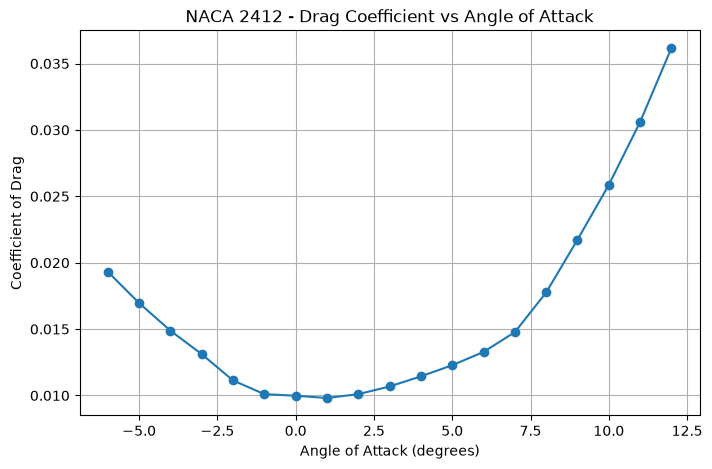

In [6]:
results_folder = Path("../results")
results_folder.mkdir(exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(data["alpha"], data["CL"], marker="o")
plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Coefficient of Lift")
plt.title("NACA 2412 - Lift Coefficient vs Angle of Attack")
plt.grid()
plt.savefig(results_folder / "naca2412_CL_vs_alpha.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(data["alpha"], data["CD"], marker="o")
plt.xlabel("Angle of Attack (degrees)")
plt.ylabel("Coefficient of Drag")
plt.title("NACA 2412 - Drag Coefficient vs Angle of Attack")
plt.grid()
plt.savefig(results_folder / "naca2412_CD_vs_alpha.png", dpi=300, bbox_inches="tight")
plt.show()